<a href="https://colab.research.google.com/github/saadkhan-dot/ML/blob/main/HousePricePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
data = {
    "Area": [800, 1000, 1200, 1500, 1800, 2000, 2200, 2500],
    "Bedrooms": [2, 2, 3, 3, 3, 4, 4, 5],
    "Price": [40, 50, 60, 75, 90, 100, 110, 125]
}

df = pd.DataFrame(data)

print("=" * 60)
print("HOUSE PRICE PREDICTION USING LINEAR REGRESSION")
print("=" * 60)
print("\nDataset Created Successfully")
print(df)

HOUSE PRICE PREDICTION USING LINEAR REGRESSION

Dataset Created Successfully
   Area  Bedrooms  Price
0   800         2     40
1  1000         2     50
2  1200         3     60
3  1500         3     75
4  1800         3     90
5  2000         4    100
6  2200         4    110
7  2500         5    125


In [ ]:
print("\n2. Dataset Information")
print("-" * 70)

print("Number of rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())

print("\nSummary Statistics:")
print(df.describe())


2. Dataset Information
----------------------------------------------------------------------
Number of rows and columns: (8, 3)

Column names: ['Area', 'Bedrooms', 'Price']

Summary Statistics:
              Area  Bedrooms       Price
count     8.000000  8.000000    8.000000
mean   1625.000000  3.250000   81.250000
std     601.783065  1.035098   30.089153
min     800.000000  2.000000   40.000000
25%    1150.000000  2.750000   57.500000
50%    1650.000000  3.000000   82.500000
75%    2050.000000  4.000000  102.500000
max    2500.000000  5.000000  125.000000


In [ ]:
X = df[["Area", "Bedrooms"]]
y = df["Price"]

print("\n3. Features (Input Data)")
print("-" * 70)
print(X)

print("\nTarget (Output Data)")
print("-" * 70)
print(y)


3. Features (Input Data)
----------------------------------------------------------------------
   Area  Bedrooms
0   800         2
1  1000         2
2  1200         3
3  1500         3
4  1800         3
5  2000         4
6  2200         4
7  2500         5

Target (Output Data)
----------------------------------------------------------------------
0     40
1     50
2     60
3     75
4     90
5    100
6    110
7    125
Name: Price, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

print("=" * 60)
print("4. TRAINING AND TESTING DATA")
print("=" * 60)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

4. TRAINING AND TESTING DATA
Training features shape: (6, 2)
Testing features shape: (2, 2)

Training target shape: (6,)
Testing target shape: (2,)


In [ ]:
print("\nTraining Data")
print("-" * 60)
print(X_train.assign(Price=y_train))

print("\nTesting Data")
print("-" * 60)
print(X_test.assign(Price=y_test))


Training Data
------------------------------------------------------------
   Area  Bedrooms  Price
0   800         2     40
7  2500         5    125
2  1200         3     60
4  1800         3     90
3  1500         3     75
6  2200         4    110

Testing Data
------------------------------------------------------------
   Area  Bedrooms  Price
1  1000         2     50
5  2000         4    100


In [ ]:
from sklearn.linear_model import LinearRegression

print("=" * 60)
print("5. LINEAR REGRESSION MODEL")
print("=" * 60)

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed successfully!")

print("\nModel Coefficients:", model.coef_)
print("Model Intercept:", model.intercept_)

5. LINEAR REGRESSION MODEL
Model training completed successfully!

Model Coefficients: [ 5.00000000e-02 -1.88736185e-15]
Model Intercept: -4.263256414560601e-14


In [ ]:
y_pred = model.predict(X_test)

print("=" * 60)
print("6. HOUSE PRICE PREDICTIONS")
print("=" * 60)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred.round(2)
})

print(results)

6. HOUSE PRICE PREDICTIONS
   Actual Price  Predicted Price
0            50             50.0
1           100            100.0


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 40)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.4f}")

MODEL EVALUATION
----------------------------------------
Mean Absolute Error (MAE): 0.00
Mean Squared Error (MSE): 0.00
Root Mean Squared Error (RMSE): 0.00
R-squared (R2): 1.0000


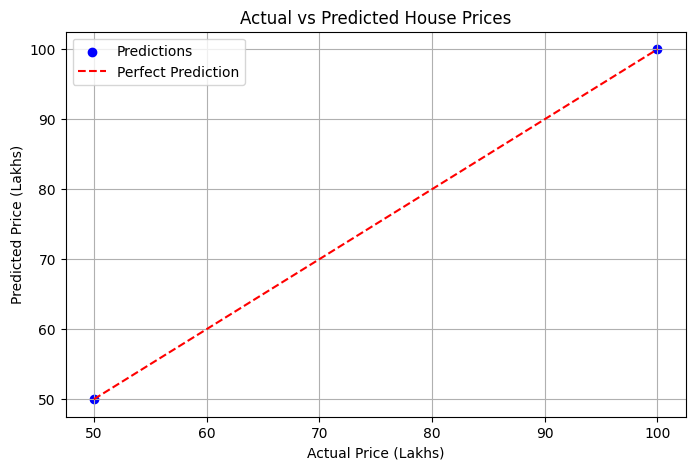

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, color="blue", label="Predictions")

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
new_house = pd.DataFrame({
    "Area": [1600],
    "Bedrooms": [3]
})

predicted_price = model.predict(new_house)

print("NEW HOUSE PRICE PREDICTION")
print("-" * 40)
print("Area: 1600 sq. ft.")
print("Bedrooms: 3")
print(f"Predicted Price: {predicted_price[0]:.2f} Lakhs")

NEW HOUSE PRICE PREDICTION
----------------------------------------
Area: 1600 sq. ft.
Bedrooms: 3
Predicted Price: 80.00 Lakhs
